In [19]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
# %% 1. Settings: three multiple regressions using the saved forward-year inputs
import numpy as np
from pathlib import Path

mf_core = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412")
mf_input_paths = {"regional": mf_core / "regional_forward_year/run_01/regional_forward_year.npy",
                  "nino": mf_core / "nino34_forward_year_tas/run_01/nino34_forward_year_tas.npy"}
mf_output_dir = mf_core / "multiple_forward_year/run_01"
mf_archive_path = mf_output_dir / "multiple_forward_year.npy"
mf_experiments = ["historical_matched", "amip_hist"]
mf_fits = {"Nino34_SEP": ["Nino34", "SEP"], "Nino34_WPWP": ["Nino34", "WPWP"],
           "Nino34_SEP_WPWP": ["Nino34", "SEP", "WPWP"]}
mf_save, mf_resume = True, True
mf_warn_condition, mf_max_condition = 30., 1e6  # Numerical diagnostics, NOT significance thresholds.
mf_plot_statistic = "regression"               # Or "partial_covariance" or original marginal "covariance".
mf_plot_vlims = None                           # Or [T_limit, R_limit], shared by EVERY fit/predictor/experiment.
mf_save_figures, mf_cmap, mf_font_scale = True, "RdBu_r", 1.

# First run/save the regional and Nino-3.4 notebooks. Their default outputs
# ALREADY contain processed x and Cov(x,y); no large response-series saves are
# needed. This notebook does not reopen raw NetCDFs or preprocess anything.
# It retains their 167 paired starts (March 2000–January 2014), raw means first,
# monthly detrending/deseasonalization second, and y at lags 0,...,11.
# Nino34 is the member-specific monthly tas proxy, not SST, ONI, or RONI.
# Load/plot only: run cells 1, 7, 8, 9. Calculation/save: cells 1–6.




In [34]:
# %% 2. Small helpers: save safely and check that the two archives describe the SAME y
def mf_save_bundle(path, bundle, *, replace=False):
    """Atomic per-model save; an interrupted write cannot corrupt the destination."""
    import os, tempfile
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".tmp", delete=False) as stream:
            temporary = Path(stream.name)
            np.save(stream, bundle, allow_pickle=True)
            stream.flush()
            os.fsync(stream.fileno())
        if replace:
            os.replace(temporary, path)
        else:
            os.link(temporary, path)
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()


def mf_fingerprint(settings):
    import hashlib, pickle
    return hashlib.sha256(pickle.dumps(settings, protocol=4)).hexdigest()


def mf_check_inputs(regional, nino, experiments):
    """Check grid, paired dates, processing, raw-source identity, and member IDs.

    Return member IDs and the positional order needed to align each archive.
    Matching is WITHIN an experiment/model, never between AMIP and coupled.
    Different masks/processing are rejected, not silently intersected/refitted.
    """
    for key in ["lat", "lon", "raw_time", "time", "response_end"]:
        if not np.array_equal(regional["coordinates"][key], nino["coordinates"][key]):
            raise ValueError(f"Archives disagree on {key}; regenerate with matching settings.")
    for key in ["weights", "response_support"]:
        if not np.array_equal(regional[key], nino[key]):
            raise ValueError(f"Archives disagree on {key}; use the same grid/response mask.")
    for key in ["window", "ddof", "preprocessing_tag", "preprocessing_source", "operation_order"]:
        if regional["settings"][key] != nino["settings"][key]:
            raise ValueError(f"Archives disagree on {key}; check preprocessing before combining fits.")
    if regional["settings"]["ddof"] != 1 or nino["settings"].get("index_smoothing_months") != 1:
        raise ValueError("Expected sample covariances (ddof=1) and the unsmoothed monthly Nino-3.4 proxy.")
    if "Source unavailable" in regional["settings"]["preprocessing_source"]:
        print("Note: preprocessing source was unavailable; consistency relies on your saved preprocessing_tag.")

    # The joint fit requires EXACTLY the same response realization in both
    # archives. File fingerprints catch different raw files/versions even when
    # the model names match. Member order may differ; it is aligned explicitly.
    ids, order = {e: {} for e in experiments}, {name: {e: {} for e in experiments} for name in ["regional", "nino"]}
    jobs = [("obs", "ERA5_CERES")] + [(e, m) for e in experiments for m in regional["model_names"][e]]
    for experiment in experiments:
        models = regional["model_names"][experiment]
        if not models or len(set(models)) != len(models) or set(models) != set(nino["model_names"][experiment]):
            raise ValueError(f"{experiment}: model sets must be nonempty, unique, and match between archives.")
    for experiment, model in jobs:
        if regional["sources"][experiment][model] != nino["sources"][experiment][model]:
            raise ValueError(f"{experiment}/{model}: raw T/R file fingerprints differ between archives.")
        if experiment == "obs":
            continue
        reference = np.asarray(regional["member_ids"][experiment][model]).astype(str)
        if not len(reference) or len(set(reference)) != len(reference):
            raise ValueError(f"{experiment}/{model}: empty or duplicate member IDs.")
        ids[experiment][model] = reference
        for name, archive in [("regional", regional), ("nino", nino)]:
            labels = np.asarray(archive["member_ids"][experiment][model]).astype(str)
            if len(set(labels)) != len(labels) or set(labels) != set(reference):
                raise ValueError(f"{experiment}/{model}: member IDs differ between archives.")
            positions = {label: i for i, label in enumerate(labels)}
            order[name][experiment][model] = np.array([positions[label] for label in reference])
    return ids, order




In [35]:
# %% 3. Scientific calculation: recover the joint OLS fit from saved cross-moments
def calculate_multiple_forward_year(predictor_values, support, *, max_condition=1e6):
    """One member, one predictor set. Input order is the returned predictor order.

    predictor_values = {name: original_single_predictor_values, ...}.
    All predictors have the same complete dates and response field y.
    Output slopes/partial covariances: (predictor,lat,lon); x: (time,predictor).
    The intercept is fitted; processing makes it approximately zero.
    """
    support = np.asarray(support, dtype=bool)
    if support.ndim != 2 or not support.any() or len(predictor_values) < 2:
        raise ValueError("Need at least two predictors and nonempty 2-D response support.")
    if not np.isfinite(max_condition) or max_condition <= 1:
        raise ValueError("max_condition must be finite and greater than one.")
    inputs = list(predictor_values.values())
    x_saved = [np.asarray(v["x"], dtype=float) for v in inputs]
    if any(x.ndim != 1 or x.shape != x_saved[0].shape for x in x_saved):
        raise ValueError("Each processed predictor must have the same 1-D paired dates.")
    X, X_raw = np.column_stack(x_saved), np.column_stack([v["x_raw"] for v in inputs])
    n, p = X.shape
    if n <= p+1 or X_raw.shape != X.shape or not np.isfinite(X).all() or not np.isfinite(X_raw).all():
        raise ValueError("Invalid predictor shape/values or too few paired samples.")
    x_mean = X.mean(axis=0)
    Xc = X - x_mean
    sigma = Xc.std(axis=0, ddof=1)
    if np.any(sigma <= 100*np.finfo(float).eps*np.maximum(1., np.max(np.abs(X_raw), axis=0))):
        raise ValueError("A predictor has no resolved variability after preprocessing.")
    if not np.allclose(sigma, np.array([v["sigma_x"] for v in inputs]), rtol=1e-9, atol=1e-12):
        raise ValueError("Saved sigma_x does not match saved x; check source archives.")
    if np.any(np.abs(x_mean) > 1e-9*sigma):
        raise ValueError("Expected centered processed predictors from the forward-year notebooks.")

    # Numerical rescaling only: Z has unit sample variance. The returned beta
    # is subsequently converted BACK to a change per kelvin of each index.
    # Cov(X,y) = Cov(X,X) @ beta is the joint OLS normal equation. These are
    # sufficient statistics: we do NOT need to save or reopen y(t,lat,lon).
    Z = Xc / sigma
    singular = np.linalg.svd(Z, compute_uv=False)
    rank = np.sum(singular > max(Z.shape)*np.finfo(float).eps*singular[0])
    condition = singular[0]/singular[-1] if singular[-1] > 0 else np.inf
    if rank < p or condition > max_condition:
        raise ValueError(f"Predictors cannot define a stable unique fit: rank={rank}/{p}, condition={condition:.3g}.")
    covariance_x = Xc.T @ Xc / (n-1)
    correlation_x = Z.T @ Z / (n-1)

    # QR gives Z'Z = R'R. Solve two small triangular systems rather than
    # explicitly inverting the covariance matrix for every map cell.
    _, upper = np.linalg.qr(Z, mode="reduced")
    inverse_upper = np.linalg.solve(upper, np.eye(p))
    inverse_correlation = (n-1) * inverse_upper @ inverse_upper.T
    vif = np.diag(inverse_correlation)
    unique_variance = sigma**2 / vif
    result = {"x_raw": X_raw.copy(), "x": X.copy(), "sigma_x": sigma,
              "predictor_covariance": covariance_x, "predictor_correlation": correlation_x,
              "vif": vif, "unique_x_variance": unique_variance, "condition_number": float(condition)}

    # Each row of Cxy is a saved MARGINAL covariance with the very same y.
    # Joint coefficients are conditional: beta_k is the fitted change in y
    # per 1 K of x_k while the other predictors are held fixed.
    for field in ["T", "R"]:
        cov_maps = np.stack([v[f"covariance_{field}"] for v in inputs])
        slopes = np.stack([v[f"regression_{field}"] for v in inputs])
        intercepts = np.stack([v[f"intercept_{field}"] for v in inputs])
        if any(a.shape != (p,) + support.shape for a in [cov_maps, slopes, intercepts]):
            raise ValueError(f"{field}: saved maps do not match predictor/grid dimensions.")
        if any(not np.isfinite(a[:, support]).all() for a in [cov_maps, slopes, intercepts]):
            raise ValueError(f"{field}: missing moments on the common response support.")
        Cxy = cov_maps[:, support]
        np.testing.assert_allclose(slopes[:, support]*sigma[:, None]**2, Cxy, rtol=1e-8, atol=1e-11)
        # Recover mean(y) from its original univariate intercept; all predictors
        # must imply the same mean because they used the identical response.
        y_means = intercepts[:, support] + slopes[:, support]*x_mean[:, None]
        np.testing.assert_allclose(y_means, np.broadcast_to(y_means[0], y_means.shape), rtol=1e-8, atol=1e-10)
        right = (n-1) * Cxy / sigma[:, None]
        beta_standardized = np.linalg.solve(upper, np.linalg.solve(upper.T, right))
        beta = beta_standardized / sigma[:, None]
        intercept = y_means[0] - x_mean @ beta
        np.testing.assert_allclose(covariance_x @ beta, Cxy, rtol=1e-7, atol=1e-10)

        # Covariance has no single automatic "multiple" version. Keep the
        # original marginal covariance AND a clearly named partial covariance.
        # Remove the other predictors from BOTH x_k and y: Cov(x_k*,y*) =
        # beta_k * Var(x_k*) = beta_k * sigma_k^2/VIF_k. This is NOT a sum
        # decomposition of total response variance or a causal attribution.
        for key, values in [("regression", beta), ("covariance", Cxy),
                            ("partial_covariance", beta*unique_variance[:, None])]:
            mapped = np.full((p,) + support.shape, np.nan)
            mapped[:, support] = values
            result[f"{key}_{field}"] = mapped
        mapped = np.full(support.shape, np.nan)
        mapped[support] = intercept
        result[f"intercept_{field}"] = mapped
    return result




In [36]:
# %% 4. Load/check prerequisites, label every axis, and allocate the outputs
mf_inputs = {name: np.load(path, allow_pickle=True).item() for name, path in mf_input_paths.items()}
mf_regional, mf_nino = mf_inputs["regional"], mf_inputs["nino"]
mf_member_ids, mf_member_order = mf_check_inputs(mf_regional, mf_nino, mf_experiments)
mf_models = {e: list(mf_regional["model_names"][e]) for e in mf_experiments}
if set(mf_models["historical_matched"]) != set(mf_models["amip_hist"]):
    raise ValueError("AMIP and historical_matched must contain the same model population.")
mf_coordinates = mf_regional["coordinates"]
mf_weights, mf_support = mf_regional["weights"], mf_regional["response_support"]
mf_regions = {"Nino34": mf_nino["regions"]["Nino34"],
              "SEP": mf_regional["regions"]["SEP"], "WPWP": mf_regional["regions"]["WPWP"]}
for fit, names in mf_fits.items():
    if len(names) < 2 or len(set(names)) != len(names) or not set(names).issubset(mf_regions):
        raise ValueError(f"{fit}: select at least two distinct available predictors.")

mf_quantity_info = {
    "x_raw": {"dims": ("time", "predictor"), "units": "K", "meaning": "Absolute regional temperature at paired start month"},
    "x": {"dims": ("time", "predictor"), "units": "K", "meaning": "Saved monthly detrended/deseasonalized predictors"},
    "sigma_x": {"dims": ("predictor",), "units": "K", "meaning": "Sample temporal SD of each processed predictor"},
    "predictor_covariance": {"dims": ("predictor", "predictor"), "units": "K2", "meaning": "Covariance among processed predictors"},
    "predictor_correlation": {"dims": ("predictor", "predictor"), "units": "1", "meaning": "Correlation among processed predictors"},
    "vif": {"dims": ("predictor",), "units": "1", "meaning": "Var(x_k)/Var(x_k after linearly removing the other predictors); collinearity diagnostic"},
    "unique_x_variance": {"dims": ("predictor",), "units": "K2", "meaning": "Sample variance remaining in x_k after fitting all other predictors"},
    "condition_number": {"dims": (), "units": "1", "meaning": "Largest/smallest singular value of centered, unit-SD predictor design"}}
for field, slope_units, cov_units, field_units in [("T", "K K-1", "K2", "K"), ("R", "W m-2 K-1", "K W m-2", "W m-2")]:
    mf_quantity_info[f"regression_{field}"] = {"dims": ("predictor", "lat", "lon"), "units": slope_units,
        "meaning": f"Conditional OLS slope of processed forward-mean {field}; other predictors held fixed"}
    mf_quantity_info[f"covariance_{field}"] = {"dims": ("predictor", "lat", "lon"), "units": cov_units,
        "meaning": "Original MARGINAL covariance, unchanged from single-predictor fits"}
    mf_quantity_info[f"partial_covariance_{field}"] = {"dims": ("predictor", "lat", "lon"), "units": cov_units,
        "meaning": "Covariance after removing other predictors from BOTH x_k and y; ddof=1, not residual degrees of freedom"}
    mf_quantity_info[f"intercept_{field}"] = {"dims": ("lat", "lon"), "units": field_units,
        "meaning": "Joint-fit intercept on processed series; approximately zero"}

# Input archive fingerprints prevent reusing results after either prerequisite
# changes. No files are overwritten on a mismatch: choose a new run directory.
mf_input_sources = {name: {"path": str(path), "size": path.stat().st_size,
    "mtime_ns": path.stat().st_mtime_ns, "signature": mf_inputs[name]["signature"]} for name, path in mf_input_paths.items()}
mf_settings = {"schema": "multiple_forward_year_v1", "input_archives": mf_input_sources, "fits": mf_fits,
    "experiments": mf_experiments, "model_names": mf_models, "max_condition": mf_max_condition,
    "window": mf_regional["settings"]["window"], "ddof": 1,
    "preprocessing_tag": mf_regional["settings"]["preprocessing_tag"],
    "preprocessing_source": mf_regional["settings"]["preprocessing_source"]}
mf_signature = mf_fingerprint(mf_settings)
if mf_save and mf_archive_path.exists():
    previous = np.load(mf_archive_path, allow_pickle=True).item()
    if not mf_resume or previous["signature"] != mf_signature:
        raise ValueError("Existing output has different inputs/settings, or resume is disabled. Use a new output directory.")
    del previous
mf_member_values = {fit: {e: {q: {} for q in mf_quantity_info} for e in mf_experiments} for fit in mf_fits}
mf_observations = {}
print(f"Reusing {len(mf_coordinates['time'])} paired months; {len(mf_fits)} predictor sets. No raw inputs needed.")




Reusing 167 paired months; 3 predictor sets. No raw inputs needed.


In [37]:
# %% 5. Observations and each member: fit first, checkpoint each completed model
# Extract the saved x and cross-moments in the common member-ID order, then
# reuse them for each predictor set. This small loop contains no file-dependent
# field operations and no new detrending or time/mask selection.
mf_jobs = [("obs", "ERA5_CERES")] + [(e, m) for e in mf_experiments for m in mf_models[e]]
for experiment, model in mf_jobs:
    print(f"{experiment} / {model}", flush=True)
    ids = np.array(["observations"]) if experiment == "obs" else mf_member_ids[experiment][model]
    checkpoint = mf_output_dir / "checkpoints" / experiment / f"{model}.npy"
    reused = mf_save and checkpoint.exists()
    if reused:
        bundle = np.load(checkpoint, allow_pickle=True).item()
        if not mf_resume or bundle["signature"] != mf_signature or not np.array_equal(bundle["member_ids"], ids):
            raise ValueError(f"{checkpoint}: changed inputs/settings/member labels; use a new output directory.")
        print("  Reused completed model checkpoint.")
    else:
        collected = {fit: {q: [] for q in mf_quantity_info} for fit in mf_fits}
        for member, member_id in enumerate(ids):
            predictors = {}
            for name, source in [("Nino34", "nino"), ("SEP", "regional"), ("WPWP", "regional")]:
                archive = mf_inputs[source]
                if experiment == "obs":
                    predictors[name] = archive["observations"][name]
                else:
                    position = mf_member_order[source][experiment][model][member]
                    data = archive["member_values"][name][experiment]
                    if any(np.asarray(values[model]).shape[0] != len(ids) for values in data.values()):
                        raise ValueError(f"{experiment}/{model}/{name}: unexpected member axis.")
                    predictors[name] = {q: values[model][position] for q, values in data.items()}
                if np.shape(predictors[name]["x"]) != (len(mf_coordinates["time"]),):
                    raise ValueError(f"{experiment}/{model}/{name}: predictor length disagrees with paired dates.")
            for fit, names in mf_fits.items():
                result = calculate_multiple_forward_year({name: predictors[name] for name in names},
                                                          mf_support, max_condition=mf_max_condition)
                for quantity in mf_quantity_info:
                    collected[fit][quantity].append(result[quantity])
            print(f"  member {member+1}/{len(ids)} complete", flush=True)
        bundle = {"values": {fit: {q: np.stack(v) for q, v in data.items()} for fit, data in collected.items()},
                  "member_ids": ids, "signature": mf_signature, "experiment": experiment, "model": model}

    # Restore full member arrays; observations lose only their artificial
    # singleton member axis. Check shapes and finite values before summarizing.
    for fit, names in mf_fits.items():
        sizes = {"predictor": len(names), "time": len(mf_coordinates["time"]),
                 "lat": len(mf_coordinates["lat"]), "lon": len(mf_coordinates["lon"])}
        if experiment == "obs":
            mf_observations[fit] = {}
        for quantity, info in mf_quantity_info.items():
            values = np.asarray(bundle["values"][fit][quantity])
            if values.shape != (len(ids),) + tuple(sizes[d] for d in info["dims"]):
                raise ValueError(f"{fit}/{model}/{quantity}: invalid stored shape.")
            selected = values[..., mf_support] if "lat" in info["dims"] else values
            if not np.isfinite(selected).all():
                raise ValueError(f"{fit}/{model}/{quantity}: nonfinite required values.")
            if experiment == "obs":
                mf_observations[fit][quantity] = values[0]
            else:
                mf_member_values[fit][experiment][quantity][model] = values
        worst = bundle["values"][fit]["condition_number"].max()
        if worst >= mf_warn_condition:
            print(f"  Collinearity caution: {fit}, largest member condition={worst:.1f}; inspect member VIFs.")
    if mf_save and not reused:
        mf_save_bundle(checkpoint, bundle)
    del bundle




obs / ERA5_CERES
  member 1/1 complete
historical_matched / BCC-CSM2-MR
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CAMS-CSM1-0
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CESM2
  member 1/11 complete
  member 2/11 complete
  member 3/11 complete
  member 4/11 complete
  member 5/11 complete
  member 6/11 complete
  member 7/11 complete
  member 8/11 complete
  member 9/11 complete
  member 10/11 complete
  member 11/11 complete
historical_matched / CIESM
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CNRM-CM6-1-HR
  member 1/1 complete
historical_matched / CNRM-CM6-1
  member 1/29 complete
  member 2/29 complete
  member 3/29 complete
  member 4/29 complete
  member 5/29 complete
  member 6/29 complete
  member 7/29 complete
  member 8/29 complete
  member 9/29 complete
  member 10/29 complete
  member 11/29 complete
  member 12/29 complete
  member 13/29 compl

In [38]:
# %% 6. Mean member diagnostics -> model means -> equal-model MMM; save all labels
mf_model_mean_values = {fit: {e: {} for e in mf_experiments} for fit in mf_fits}
mf_MMM_values = {fit: {e: {} for e in mf_experiments} for fit in mf_fits}
for fit in mf_fits:
    for experiment, models in mf_models.items():
        for quantity in mf_quantity_info:
            data = mf_member_values[fit][experiment][quantity]
            means = {model: data[model].mean(axis=0) for model in models}
            mf_model_mean_values[fit][experiment][quantity] = means
            mf_MMM_values[fit][experiment][quantity] = np.stack([means[m] for m in models]).mean(axis=0)

# All averages are summaries of MEMBER diagnostics, including VIFs/SDs/matrices.
# They are not a regression of ensemble means, a pooled-member fit, or the VIF
# of a mean predictor series. Inspect member VIFs before interpreting big slopes.
mf_archive = {"member_values": mf_member_values, "model_mean_values": mf_model_mean_values,
    "MMM_values": mf_MMM_values, "observations": mf_observations, "fit_predictors": mf_fits,
    "coordinates": mf_coordinates, "model_names": mf_models, "member_ids": mf_member_ids,
    "quantity_info": mf_quantity_info, "regions": mf_regions, "weights": mf_weights,
    "response_support": mf_support, "settings": mf_settings, "signature": mf_signature,
    "sources": mf_regional["sources"], "input_settings": {k: a["settings"] for k, a in mf_inputs.items()},
    "metadata": {"aggregation": "Mean member diagnostics within model; equal-model arithmetic MMM",
        "predictors": "Instantaneous regional tas/t2m means, processed on paired dates; Nino34 is a tas proxy",
        "response": "Raw forward arithmetic monthly means, lags 0 through window-1, THEN monthwise trend/climatology removal",
        "regression": "Conditional per-K coefficients; intercept included; joint OLS recovered from original sample moments",
        "partial_covariance": "Covariance of x_k and y after linearly removing all other predictors from both; ddof=1",
        "radiation": "Original N/CERES sign unchanged",
        "inference": "No p-values or causal attribution; predictors may covary and forward windows overlap",
        "not_saved": "Response time series/variance were not needed; response residual maps, R-squared and uncertainty are not calculated"}}
if mf_save:
    mf_save_bundle(mf_archive_path, mf_archive, replace=mf_archive_path.exists())
    print(f"Saved: {mf_archive_path}")




Saved: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/multiple_forward_year/run_01/multiple_forward_year.npy


In [39]:
# %% 7. Load-only block and quick examples (no original archives are needed now)
# Skip this reload if calculating with mf_save=False; mf_archive is in memory.
mf_archive = np.load(mf_archive_path, allow_pickle=True).item()
mf_member_values = mf_archive["member_values"]
mf_model_mean_values, mf_MMM_values = mf_archive["model_mean_values"], mf_archive["MMM_values"]
mf_observations, mf_fit_predictors = mf_archive["observations"], mf_archive["fit_predictors"]

# Coefficient maps have one extra named predictor axis, retained in all means:
# fit, experiment, model = "Nino34_SEP_WPWP", "amip_hist", "TaiESM1"
# k = mf_fit_predictors[fit].index("SEP")
# mf_member_values[fit][experiment]["regression_R"][model][:, k]   # (member,lat,lon)
# mf_model_mean_values[fit][experiment]["regression_R"][model][k] # (lat,lon)
# mf_MMM_values[fit][experiment]["regression_R"][k]                # (lat,lon)
# mf_observations[fit]["regression_R"][k]                         # (lat,lon)
# mf_member_values[fit][experiment]["x"][model][:, :, k]           # (member,167)
# mf_member_values[fit][experiment]["vif"][model]                 # (member,predictor)
# mf_observations[fit]["predictor_correlation"]                   # (predictor,predictor)
# "covariance_R" is the old MARGINAL covariance; "partial_covariance_R" controls
# for the other predictors. Neither is a decomposition of total R variance.




In [40]:
# %% 8. Plot helper: one conditional predictor per 2x3 figure, like the original maps
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.text import Text

def plot_multiple_forward_year(archive, fit, predictor, *, statistic="regression", vlims=None,
                              cmap="RdBu_r", central_longitude=210, figsize=(15, 7.5),
                              font_scale=1., outline_controls=False, savepath=None):
    """Rows T/R; columns observations/matched coupled/AMIP; one coefficient per panel.

    Auto color limits include ALL fits/predictors/experiments for comparability.
    Black outline = selected predictor; optional grey dotted outlines = controls.
    """
    if statistic not in ["regression", "partial_covariance", "covariance"]:
        raise ValueError("Choose regression, partial_covariance, or marginal covariance.")
    names = archive["fit_predictors"][fit]
    k = names.index(predictor)
    controls = [name for name in names if name != predictor]
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    lat, lon = [np.asarray(archive["coordinates"][d]) for d in ["lat", "lon"]]
    groups = ["obs", "historical_matched", "amip_hist"]
    titles = ["Observations", "Coupled (matched)", "AMIP-hist"]
    quantities = [f"{statistic}_{field}" for field in ["T", "R"]]
    panels = np.stack([np.stack([archive["observations"][fit][q][k] if e == "obs"
        else archive["MMM_values"][fit][e][q][k] for e in groups]) for q in quantities])
    if panels.shape != (2, 3, len(lat), len(lon)):
        raise ValueError("Expected two rows of three maps on the saved grid.")
    if vlims is None:
        vlims = []
        for quantity in quantities:
            maps = [archive["observations"][f][quantity] if e == "obs" else archive["MMM_values"][f][e][quantity]
                    for f in archive["fit_predictors"] for e in groups]
            finite = np.concatenate([np.abs(a[np.isfinite(a)]) for a in maps])
            if not len(finite):
                raise ValueError(f"{quantity}: no finite plotting values.")
            vlims.append(float(np.percentile(finite, 98)) or float(finite.max()) or 1.)
    if len(vlims) != 2 or not np.isfinite(vlims).all() or np.any(np.asarray(vlims) <= 0):
        raise ValueError("vlims must contain positive finite T/R limits.")

    # Plot coefficients, not the sums of fitted contributions. Each coefficient
    # has the same per-K units as in the single-predictor notebook; the scientific
    # change is conditioning on other indices, not a different normalization.
    fig, axes = plt.subplots(2, 3, figsize=figsize, layout="constrained",
        subplot_kw={"projection": ccrs.Robinson(central_longitude=central_longitude)})
    units = [r"K K$^{-1}$", r"W m$^{-2}$ K$^{-1}$"] if statistic == "regression" else [r"K$^2$", r"K W m$^{-2}$"]
    label = {"regression": "Conditional regression", "partial_covariance": "Partial covariance",
             "covariance": "Marginal covariance"}[statistic]
    for row, field in enumerate(["T", "R"]):
        for column, experiment in enumerate(groups):
            ax = axes[row, column]
            values, plot_lon = add_cyclic_point(panels[row, column], coord=lon)
            im = ax.contourf(plot_lon, lat, values, levels=np.linspace(-vlims[row], vlims[row], 21),
                            cmap=cmap, transform=ccrs.PlateCarree(), extend="both")
            for name in ([predictor] + controls if outline_controls else [predictor]):
                outline, outline_lon = add_cyclic_point(np.asarray(archive["regions"][name], dtype=float), coord=lon)
                ax.contour(outline_lon, lat, outline, levels=[.5], colors="black" if name == predictor else ".4",
                    linewidths=1.1, linestyles="solid" if name == predictor else ":", transform=ccrs.PlateCarree(), zorder=5)
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=.5, color=".2")
            ax.set_title(f"({chr(97+3*row+column)}) {titles[column]} — spatial {field}", fontsize=12)
        bar = fig.colorbar(im, ax=list(axes[row]), orientation="horizontal", pad=.035, fraction=.055, shrink=.8, aspect=55)
        bar.set_label(f"{label}: forward-mean {field} versus {predictor}  [{units[row]}]", fontsize=11)
    c, window = archive["coordinates"], archive["settings"]["window"]
    adjustment = "holding " + " + ".join(controls) + " fixed" if statistic != "covariance" else "unadjusted; identical to single-predictor covariance"
    fig.suptitle(f"{predictor} → forward {window}-month fields; {adjustment}\n"
                 f"Paired starts: {c['time'][0]}–{c['time'][-1]} ({len(c['time'])} pairs)", fontsize=15)
    fig.supxlabel("Raw regional/forward means first; monthly detrending and deseasonalization second.\n"
                  "Mean member diagnostics → equal-model MMM. Niño-3.4 uses tas. No significance stippling.", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes




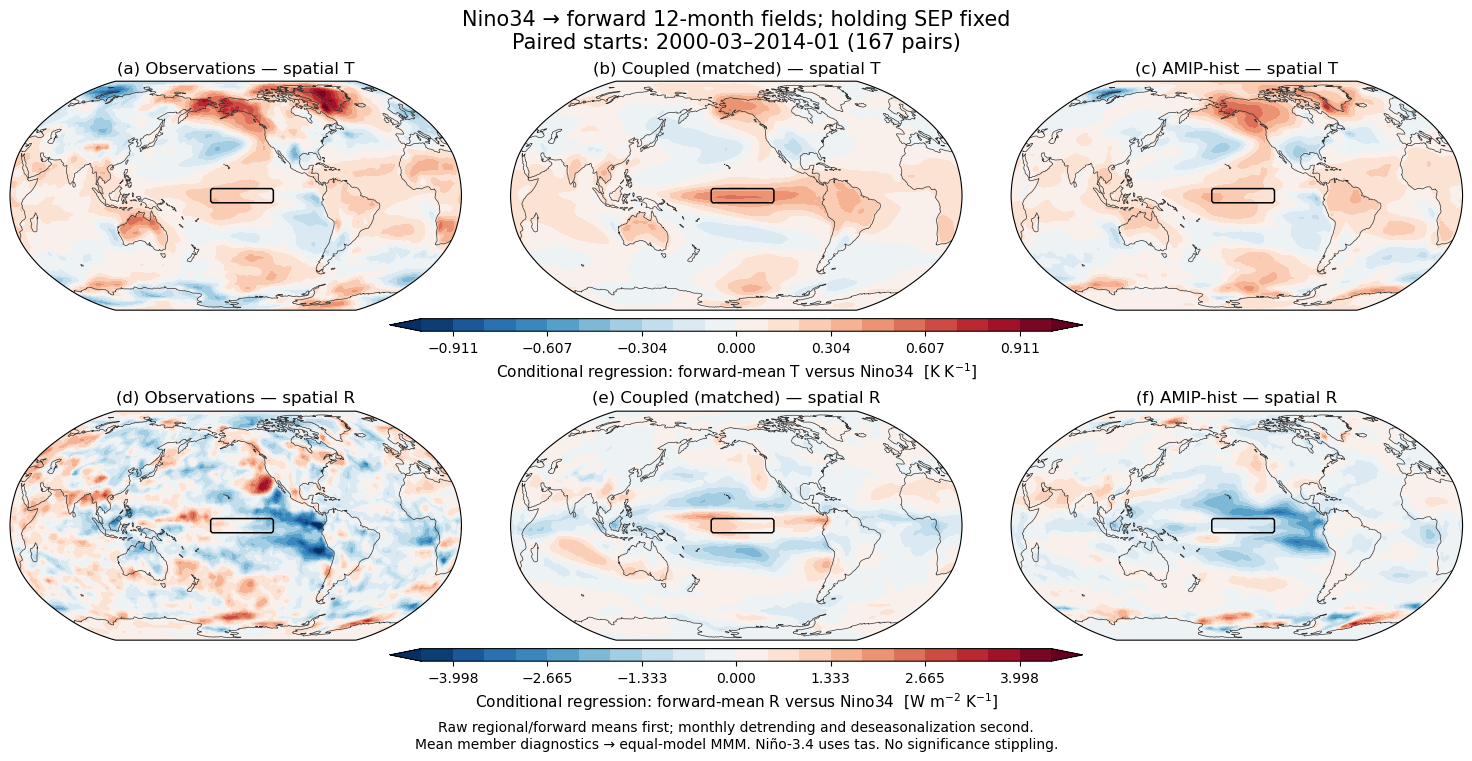

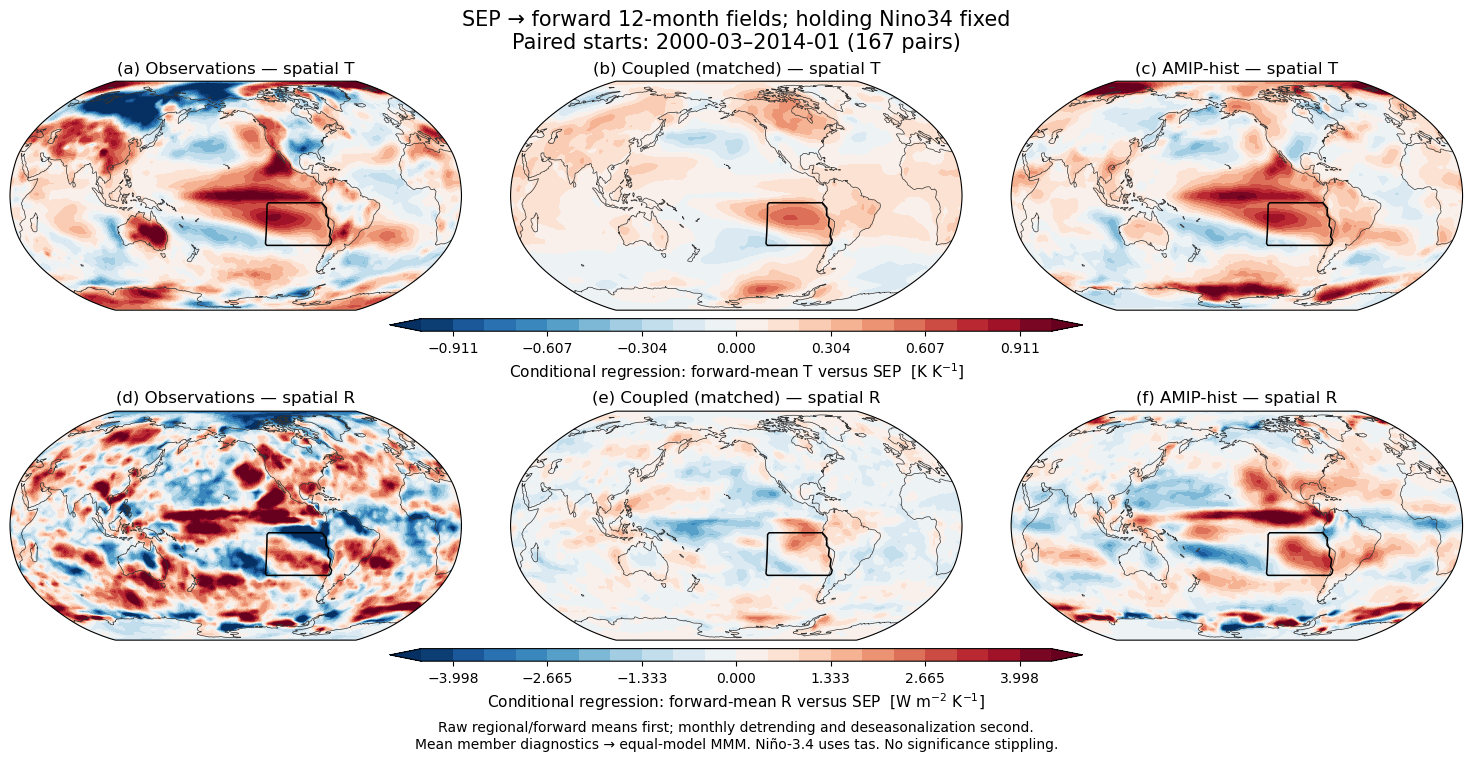

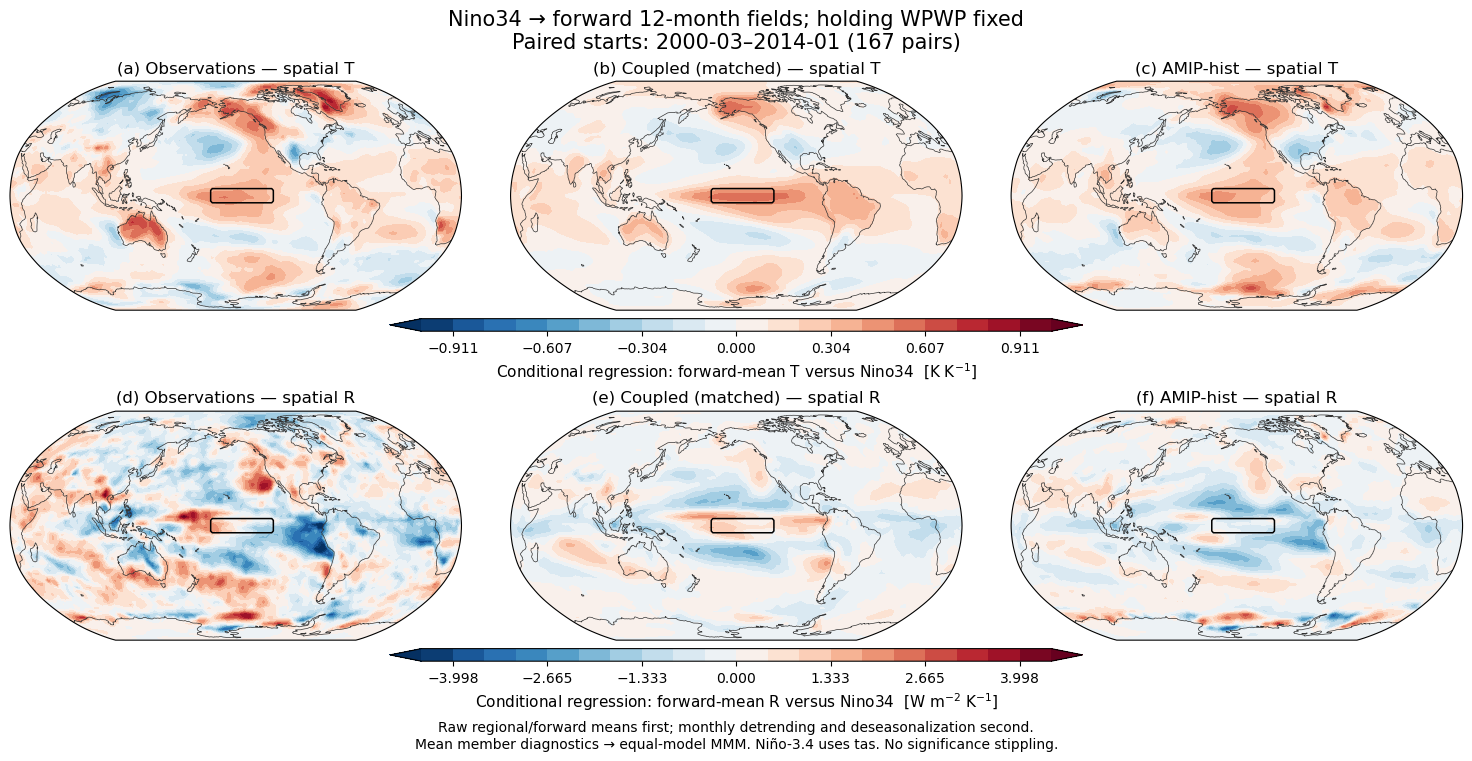

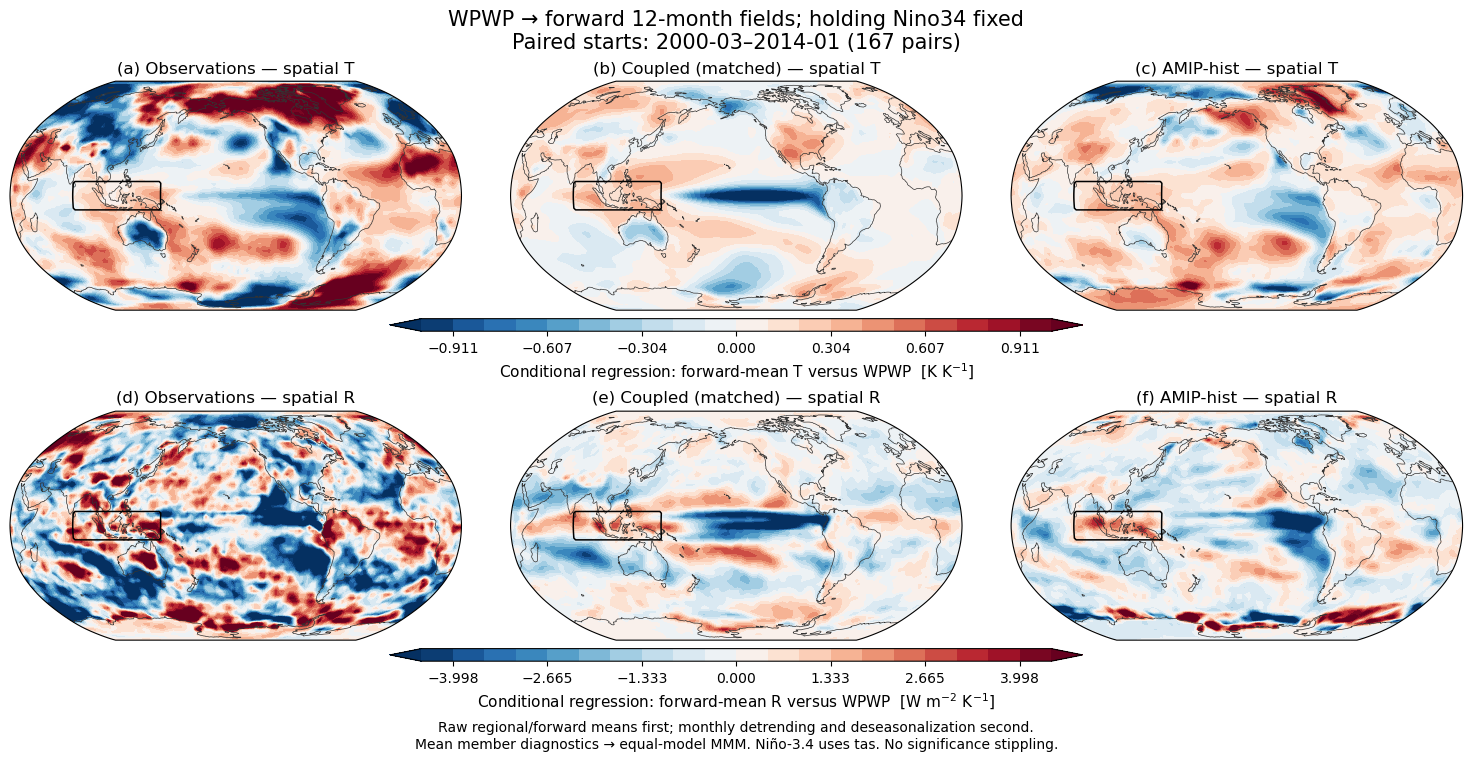

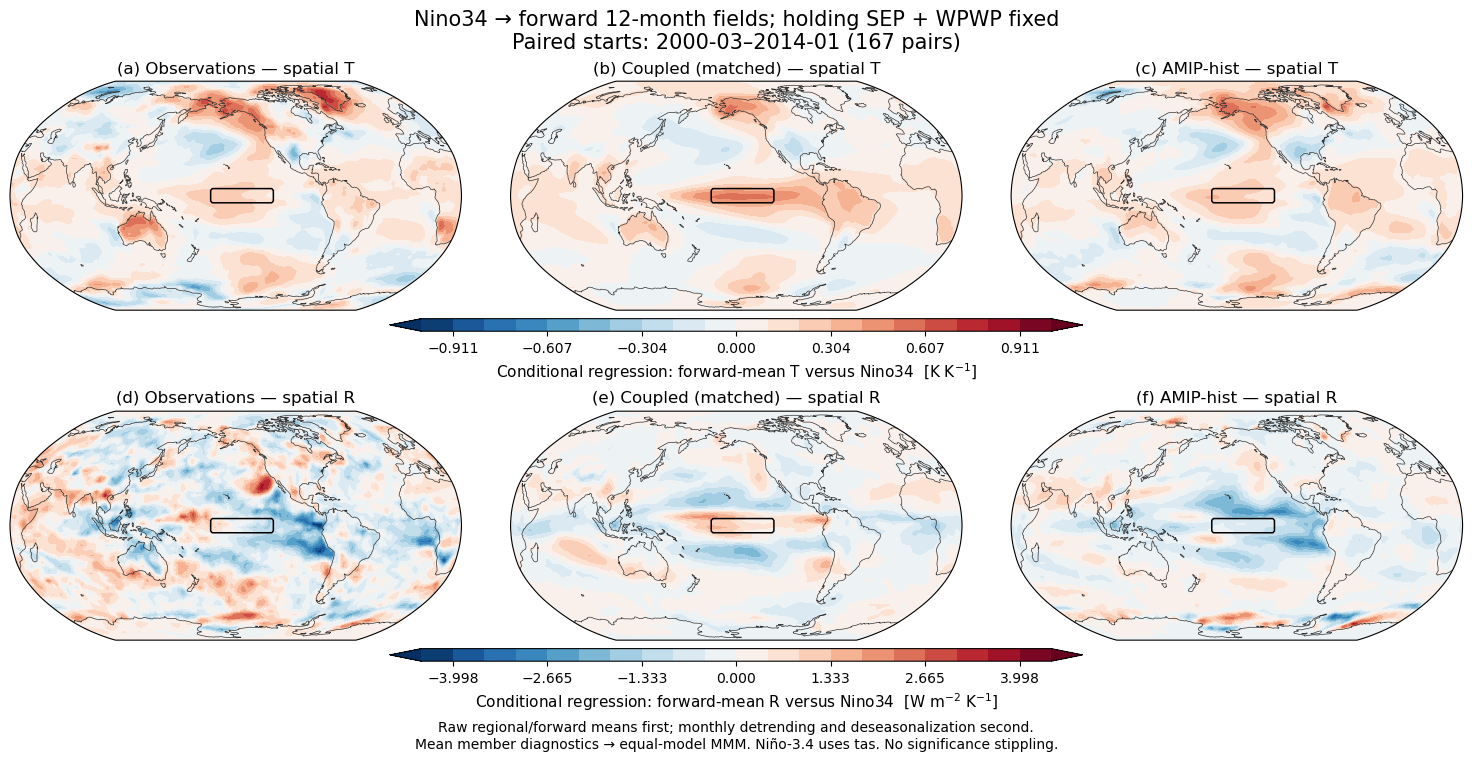

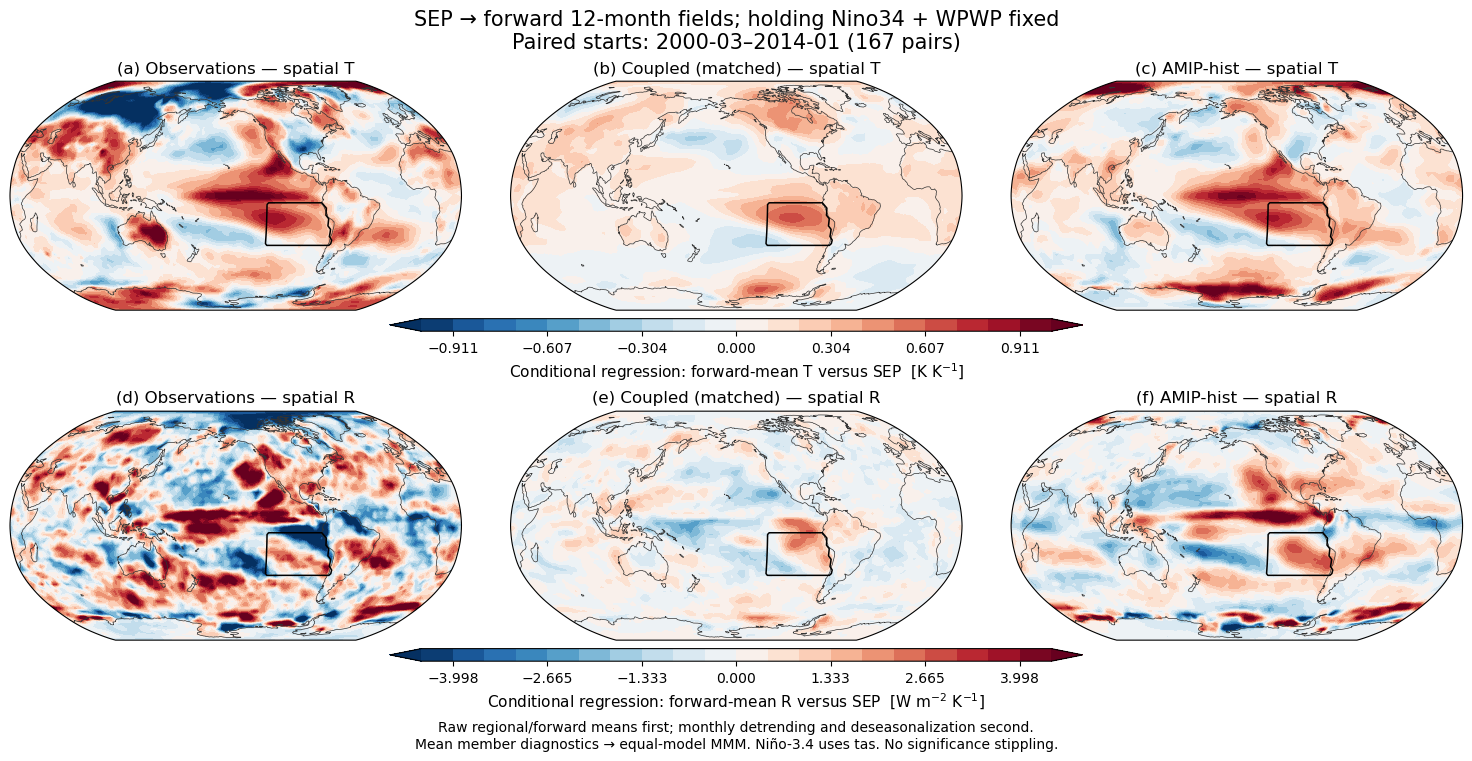

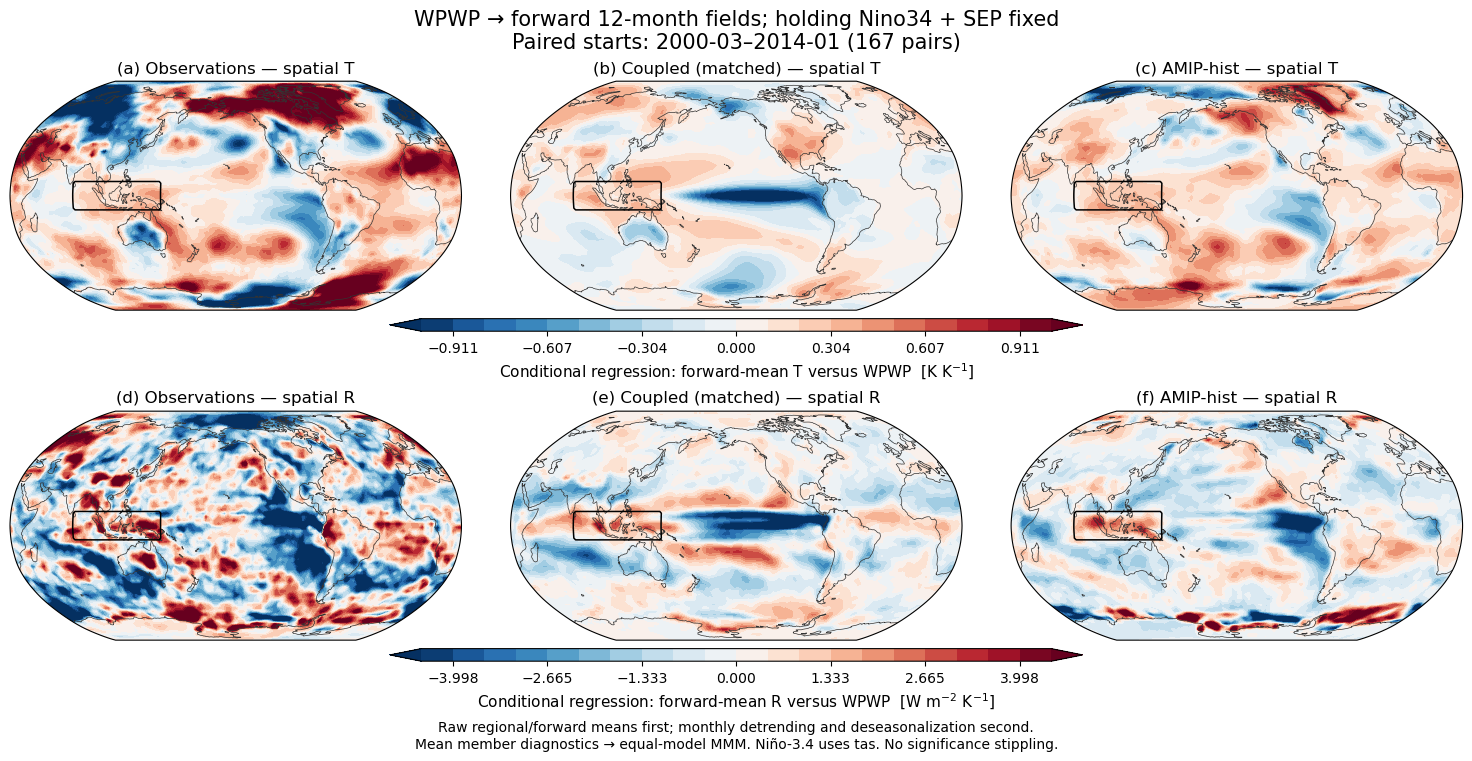

In [41]:
# %% 9. Default plots: 2 + 2 + 3 figures, one per coefficient in each joint fit
# Each is the familiar two-response by three-experiment layout. To see fewer,
# replace this list with e.g. [("Nino34_SEP_WPWP", "SEP")]. Each PNG is saved
# BEFORE plt.show(), so a notebook-renderer problem does not lose the image.
mf_plot_pairs = [(fit, predictor) for fit, names in mf_archive["fit_predictors"].items() for predictor in names]
mf_figures, mf_axes = {}, {}
for fit, predictor in mf_plot_pairs:
    destination = mf_output_dir / f"figures/{fit}_{predictor}_{mf_plot_statistic}.png" if mf_save_figures else None
    mf_figures[fit, predictor], mf_axes[fit, predictor] = plot_multiple_forward_year(
        mf_archive, fit, predictor, statistic=mf_plot_statistic, vlims=mf_plot_vlims,
        cmap=mf_cmap, font_scale=mf_font_scale, savepath=destination)
    plt.show()
